# 🎓 第6章 第2课：行为金融与投资者情绪

**本节目标**：用换手率 + 近期收益构造“情绪代理”，检验高情绪股票是否跑输。

对应原书第6章行为金融部分。

> ⚠️ 使用真实价格/成交量快照（87 只股票）；结果仅用于演示方法，不代表真实 A 股结论。

In [1]:
import sys
from pathlib import Path

def _find_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / 'src' / 'factor_zero').exists():
            return p
    raise FileNotFoundError('找不到仓库根目录，请从仓库内启动 notebook')
ROOT = _find_root()
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from factor_zero.research import (
    simulate_random_factors, p_hacking_summary,
    publication_decay_experiment, polynomial_train_test_mse, sentiment_signal,
)
from factor_zero.data import load_ashare_panel
from factor_zero.factors import build_factor_returns
from factor_zero.sorting import long_short_factor, monotonicity_test
from factor_zero.statistics import factor_summary, nw_t_stat

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC', 'DejaVu Sans']
print('✅ 环境就绪，开始学习！')

✅ 环境就绪，开始学习！


In [2]:
panel = load_ashare_panel()
ret = panel['ret']
sentiment = sentiment_signal(panel)
print('情绪面板:', sentiment.shape)
sentiment.stack().describe().round(3).to_dict()

情绪面板: (83, 81)


{'count': 6723.0,
 'mean': 0.0,
 'std': 1.439,
 'min': -4.015,
 '25%': -0.912,
 '50%': -0.256,
 '75%': 0.585,
 'max': 11.139}

## 1) 情绪代理：高换手 + 近期上涨

```
sentiment = zscore(换手率) + zscore(上期收益)
```

- 高值：高换手 + 近期涨得多 → 情绪偏热；
- 低值：低换手 + 近期跌得多 → 情绪偏冷。

**行为逻辑**：过度自信、追涨杀跌、注意力效应 → 高情绪股票被高估，未来可能跑输。

低情绪 − 高情绪: 月均 -0.713%，年化 -8.56%，NW t=-0.74
分组单调性 rho=-0.14


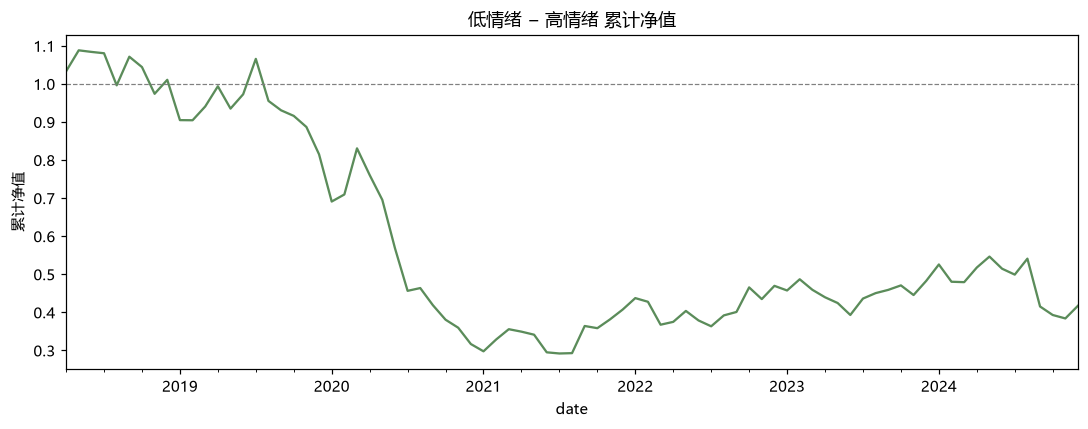

In [3]:
f_sent, port_sent, _ = long_short_factor(sentiment, ret, n_groups=10, high_minus_low=False)
s_sent = factor_summary(f_sent)
rho_sent = monotonicity_test(port_sent)['rho']
print(f'低情绪 − 高情绪: 月均 {f_sent.mean()*100:+.3f}%，年化 {s_sent["mean_ann"]*100:+.2f}%，NW t={s_sent["t_stat"]:.2f}')
print(f'分组单调性 rho={rho_sent:.2f}')
((1 + f_sent).cumprod()).plot(figsize=(10, 4), color='#5B8C5A', title='低情绪 − 高情绪 累计净值')
plt.axhline(1, color='gray', lw=.8, ls='--'); plt.ylabel('累计净值'); plt.tight_layout(); plt.show()

> 🔍 **本例结果与行为预期相反/不显著**：低情绪 − 高情绪月均约 −0.7%，NW t≈−0.74；
> 即高情绪组反而略强。样本小、区间短，不能据此否定行为异象，也不能当成交易信号。


## 2) 过度反应：短期输家 vs 短期赢家

用上期收益排序，做多输家、做空赢家。
**行为逻辑**：短期过度反应 → 输家反弹、赢家回落（短期反转）。

短期输家 − 赢家: 月均 -0.548%，年化 -6.58%，NW t=-0.62
分组单调性 rho=0.04


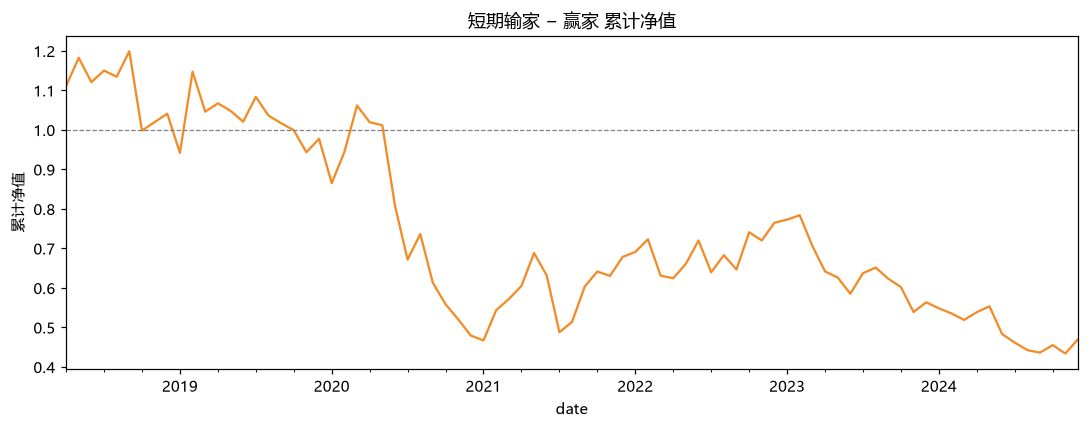

In [4]:
past1 = ret.shift(1)
f_rev, port_rev, _ = long_short_factor(past1, ret, n_groups=10, high_minus_low=False)
s_rev = factor_summary(f_rev)
rho_rev = monotonicity_test(port_rev)['rho']
print(f'短期输家 − 赢家: 月均 {f_rev.mean()*100:+.3f}%，年化 {s_rev["mean_ann"]*100:+.2f}%，NW t={s_rev["t_stat"]:.2f}')
print(f'分组单调性 rho={rho_rev:.2f}')
((1 + f_rev).cumprod()).plot(figsize=(10, 4), color='#F28C28', title='短期输家 − 赢家 累计净值')
plt.axhline(1, color='gray', lw=.8, ls='--'); plt.ylabel('累计净值'); plt.tight_layout(); plt.show()

In [5]:
pd.DataFrame({'低情绪-高情绪': s_sent, '短期输家-赢家': s_rev}).T[
    ['mean_ann', 'vol_ann', 'sharpe', 't_stat', 'max_drawdown', 'win_rate']
].round(4)

,mean_ann,vol_ann,sharpe,t_stat,max_drawdown,win_rate
低情绪-高情绪,-0.0856,0.2936,-0.2916,-0.7428,-0.7320,0.4321
短期输家-赢家,-0.0658,0.3010,-0.2185,-0.6151,-0.6382,0.4568


## 3) 行为金融的四个来源

| 来源 | 含义 | 例子 |
|---|---|---|
| 套利限制 | 错误定价难以被套利纠正 | 做空成本、流动性、噪声交易者风险 |
| 预期偏差 | 对未来的判断有系统误差 | 过度自信、代表性、锚定 |
| 风险偏好偏差 | 对风险的态度不一致 | 彩票偏好、损失厌恶、处置效应 |
| 认知限制 | 注意力/信息处理有限 | 注意力效应、分类思维、框架效应 |

> 行为异象要成立，通常需要“错误定价 + 套利限制”同时存在；否则套利者会把价格纠回来。

## ✋ 试一试

1. 把情绪代理改成“只有换手率”，结果怎么变？
2. 把上期收益换成过去 12 个月收益，情绪代理还是反转吗？
3. 把多空方向反过来，t 值符号怎么变？

## ✅ 本节小结

- 情绪代理 = 换手率 + 近期收益；高情绪可能对应高估；
- 短期反转可以看作过度反应的表现；
- 行为异象需要“错误定价 + 套利限制”；
- 真实样本小，结果不能直接外推。

> 下一课：机器学习——强大但容易过拟合。